# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [14]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [15]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [17]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

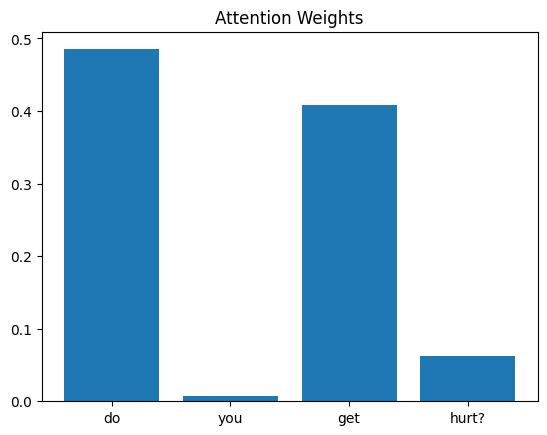

In [19]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest Attention Word: do


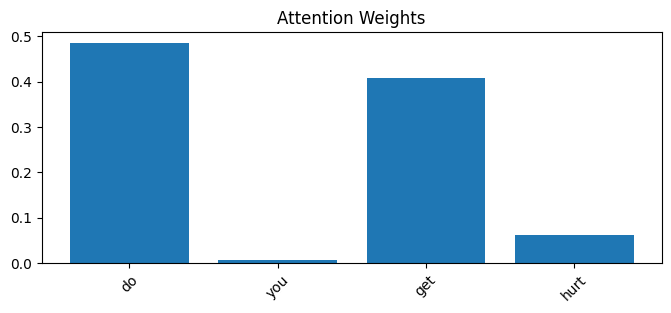

Question: do you have fingers?
Highest Attention Word: do


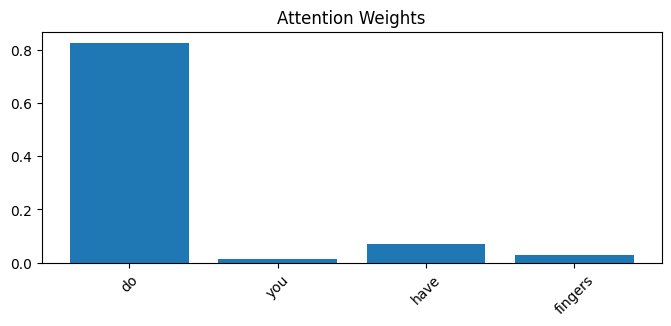

Question: do you ever breathe
Highest Attention Word: do


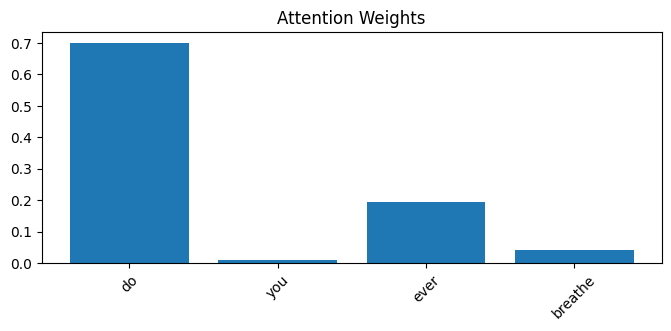

In [20]:
# Select three questions
indices = [0, 1, 2]

model.eval()

for i in indices:
    question = df["question"].iloc[i]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    word_ids = X[i][X[i] != 0].tolist()
    words = [tokenizer.index_word[w] for w in word_ids]
    attention = weights[0, :len(words)].tolist()

    # Find the word with highest attention
    highest_word = words[attention.index(max(attention))]

    print("Question:", question)
    print("Highest Attention Word:", highest_word)

    plt.figure(figsize=(8, 3))
    plt.bar(words, attention)
    plt.title("Attention Weights")
    plt.xticks(rotation=45)
    plt.show()


Yes, most of the words with the highest attention weights are important for understanding the questions. The model focuses on "breathe" and "fingers", which are meaningful words. However, for the third question, it focuses on "get" instead of "hurt". This shows that attention does not always focus on the most important word.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: do you get hurt?
Highest Attention Word: do


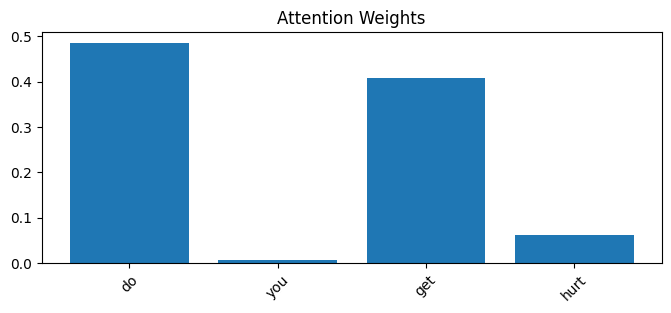

Question: do you have fingers?
Highest Attention Word: do


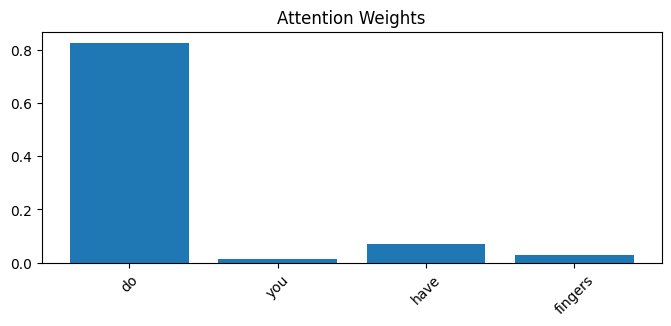

In [21]:
# Select two different questions with the same answer
similar_questions = df[
    df.duplicated("answer_id", keep=False)
]

group = next(
    group for _, group in similar_questions.groupby("answer_id")
    if group["question"].nunique() >= 2
)

indices = group.drop_duplicates("question").index[:2]

model.eval()

for i in indices:
    question = df.loc[i, "question"]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    word_ids = X[i][X[i] != 0].tolist()
    words = [tokenizer.index_word[w] for w in word_ids]
    attention = weights[0, :len(words)].tolist()

    # Find the highest attention word
    highest_word = words[attention.index(max(attention))]

    print("Question:", question)
    print("Highest Attention Word:", highest_word)

    plt.figure(figsize=(8, 3))
    plt.bar(words, attention)
    plt.title("Attention Weights")
    plt.xticks(rotation=45)
    plt.show()


The model gives different attention weights to different questions. In the first question, it focuses on "get", while in the second question, it focuses on "fingers". This shows that attention changes depending on the words in each question.